# ❤️ Heart Disease Prediction Analysis

## Project Overview

This project analyzes heart disease data using
Exploratory Data Analysis and Machine Learning.

### Objectives
- Understand patient data
- Perform data analysis
- Visualize important features
- Build a Machine Learning model
- Predict heart disease

In [2]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [3]:
# Load Dataset

df = pd.read_csv("C:/Users/hp/Downloads/heart.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
df.head()

Dataset Loaded Successfully!
Dataset Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
# Data Understanding

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000



Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Records:
723

Target Distribution:
target
1    526
0    499
Name: count, dtype: int64


In [5]:
# Data Cleaning

# Check duplicate records
print("Before Cleaning:", df.shape)

# Remove duplicate records
df = df.drop_duplicates()

print("After Cleaning:", df.shape)

# Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum().sum())

# Check duplicate records again
print("\nRemaining Duplicates:", df.duplicated().sum())

Before Cleaning: (1025, 14)
After Cleaning: (302, 14)

Missing Values After Cleaning:
0

Remaining Duplicates: 0


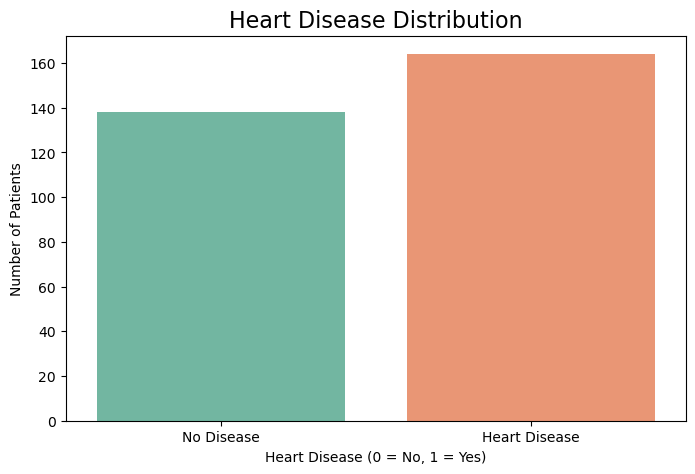

In [6]:
# Heart Disease Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Heart Disease Distribution", fontsize=16)
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Disease", "Heart Disease"])

plt.show()

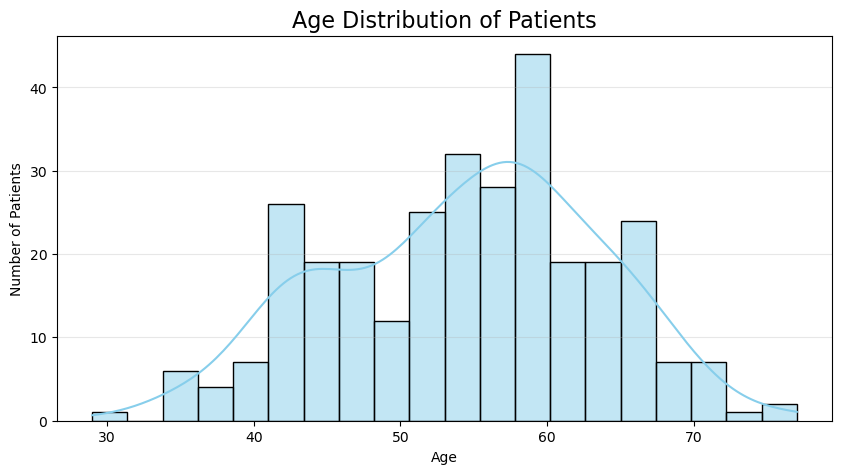

In [7]:
# Age Distribution Analysis

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution of Patients", fontsize=16)
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.grid(axis="y", alpha=0.3)
plt.show()

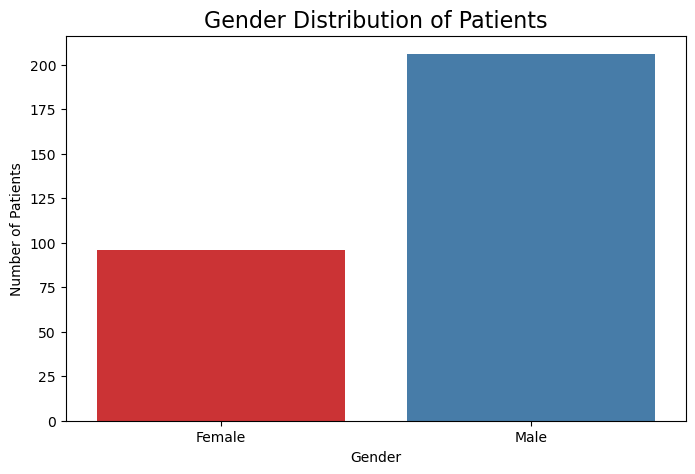

In [8]:
# Gender Distribution Analysis

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="sex",
    palette="Set1",
    legend=False
)

plt.title("Gender Distribution of Patients", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["Female", "Male"])

plt.show()

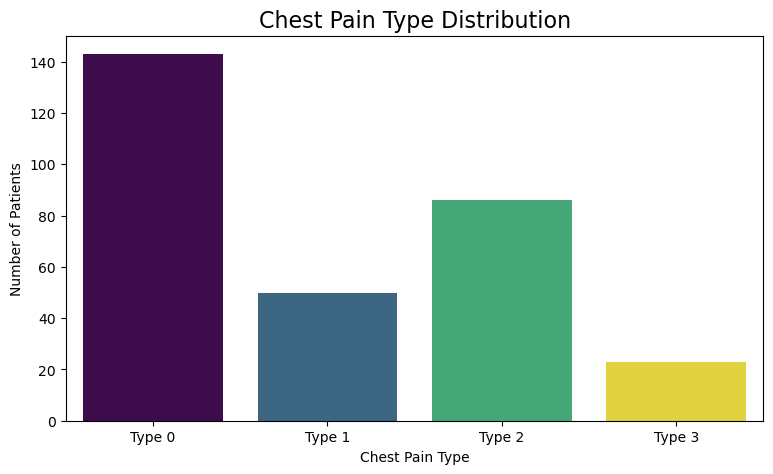

In [9]:
# Chest Pain Type Analysis

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="cp",
    hue="cp",
    palette="viridis",
    legend=False
)

plt.title("Chest Pain Type Distribution", fontsize=16)
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.xticks([0, 1, 2, 3], [
    "Type 0", "Type 1", "Type 2", "Type 3"
])

plt.show()

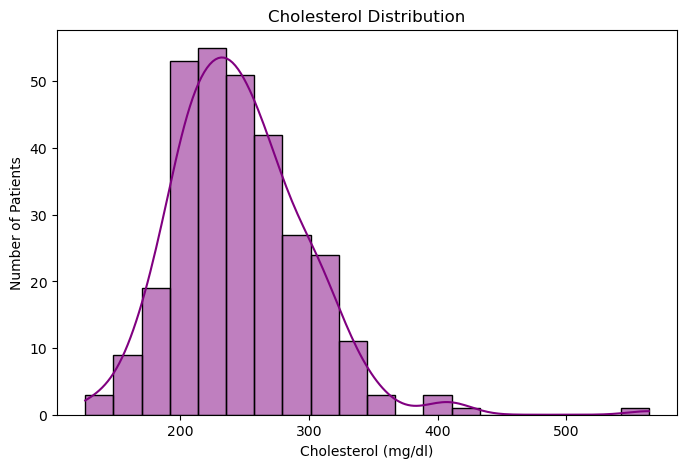

In [10]:
# Cholesterol Analysis

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="chol", bins=20, kde=True,
             color="purple")

plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol (mg/dl)")
plt.ylabel("Number of Patients")

plt.show()

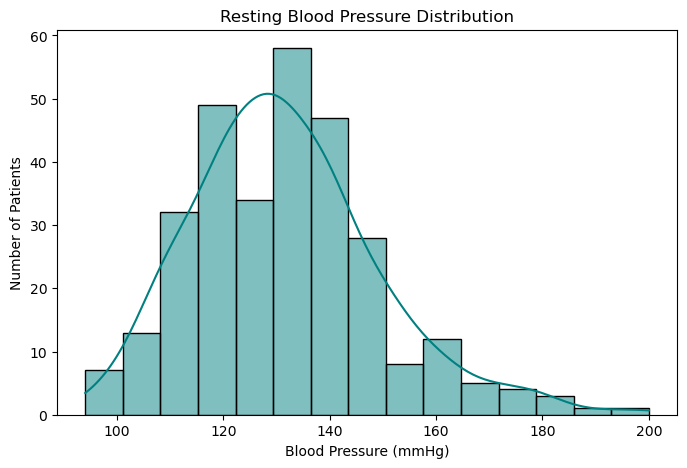

In [11]:
# Blood Pressure Analysis

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="trestbps", bins=15,
             kde=True, color="teal")

plt.title("Resting Blood Pressure Distribution")
plt.xlabel("Blood Pressure (mmHg)")
plt.ylabel("Number of Patients")

plt.show()

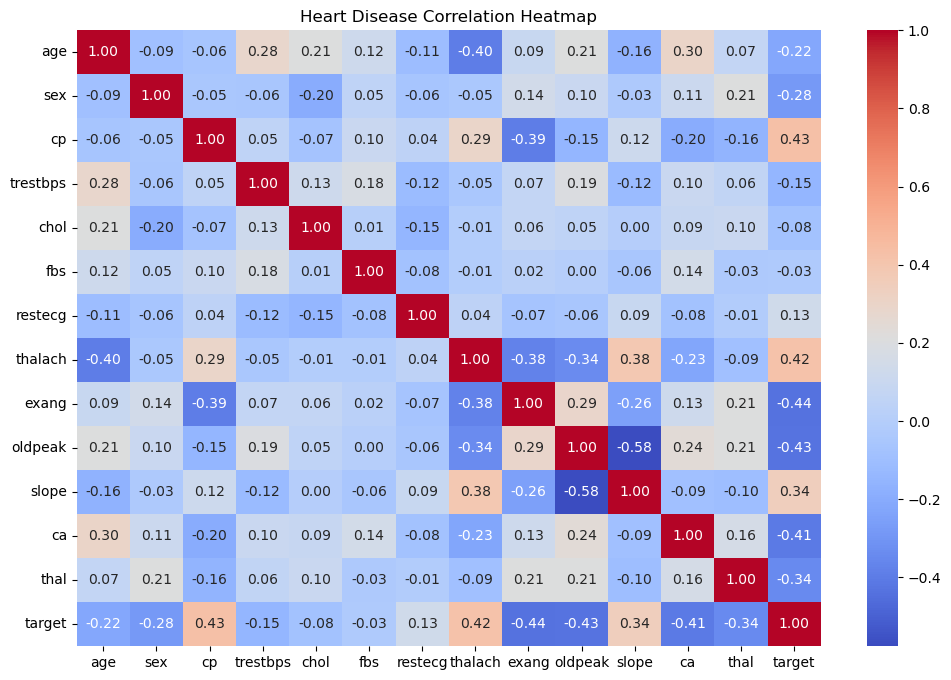

In [12]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heart Disease Correlation Heatmap")
plt.show()

In [13]:
# Feature Selection

X = df.drop("target", axis=1)
y = df["target"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

Features Shape: (302, 13)
Target Shape: (302,)

Selected Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [14]:
# Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Train Test Split Completed!")

Training Data: (241, 13)
Testing Data: (61, 13)
Train Test Split Completed!


In [15]:
# Random Forest Model Training

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [16]:
# Model Evaluation

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Performance")
print("----------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Performance
----------------------
Accuracy : 75.41 %
Precision: 76.47 %
Recall   : 78.79 %
F1 Score : 77.61 %

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



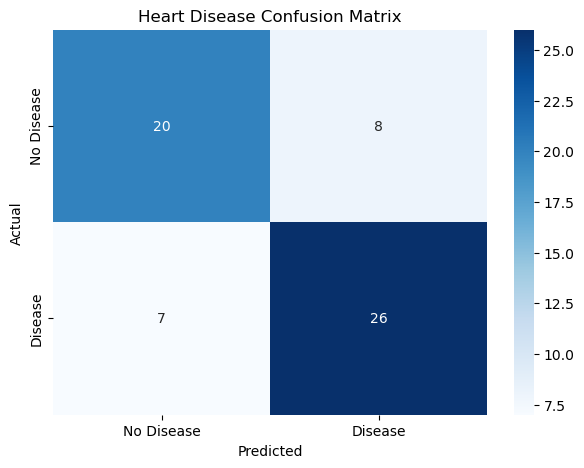

In [17]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Heart Disease Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

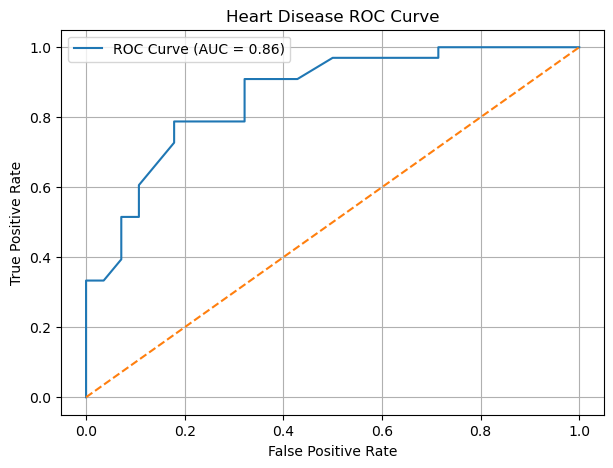

ROC-AUC Score: 0.86


In [18]:
# ROC Curve & AUC

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Heart Disease ROC Curve")

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 2))

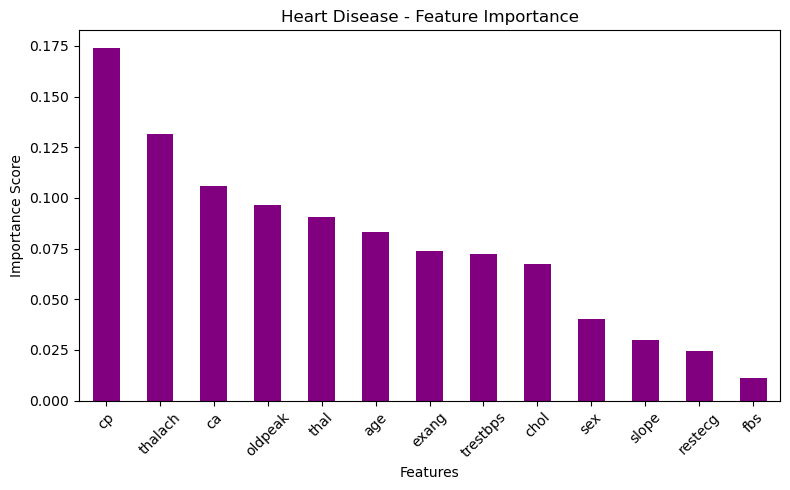

In [19]:
# Feature Importance

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.plot(kind="bar", color="purple")

plt.title("Heart Disease - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

rf_accuracy = model.score(X_test, y_test)
dt_accuracy = dt.score(X_test, y_test)

comparison = pd.Series({
    "Random Forest": rf_accuracy,
    "Decision Tree": dt_accuracy
})

comparison.plot(kind="bar", color=["purple", "skyblue"],
                figsize=(6, 4), ylim=(0, 1),
                title="Model Accuracy Comparison")

plt.ylabel("Accuracy")
plt.show()

# ❤️ Project Conclusion

- Analyzed 1,025 heart disease records.
- Cleaned duplicate records.
- Performed EDA and data visualization.
- Trained Random Forest and Decision Tree models.
- Achieved ROC-AUC score of 0.86.
- Identified important heart disease features.

**Project Status: Successfully Completed!**

In [23]:
%%writefile heart.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import os

# PAGE CONFIG
st.set_page_config(
    page_title="Heart Disease Dashboard",
    page_icon="❤️",
    layout="wide"
)

# DESIGN
st.markdown("""
<style>
.stApp {
    background: #Oe1117;
}
.heart {
    font-size: 65px;
    display: inline-block;
    animation: rotate 4s linear infinite;
}
@keyframes rotate {
    0% {transform: rotate(0deg);}
    100% {transform: rotate(360deg);}
}
.title {
    font-size: 34px;
    font-weight: bold;
    color: white;
}
.subtitle {
    color: #b8b8c7;
    font-size: 15px;
}
div[data-testid="stMetric"] {
    background: #1e1e2e;
    padding: 18px;
    border-radius: 12px;
    border-left: 4px solid #b35bba;
    box-shadow: 0 2px 8px #333;
}
</style>
""", unsafe_allow_html=True)

# MODEL
@st.cache_resource
def load_model():
    return joblib.load("heart_model.pkl")

try:
    model = load_model()
except Exception as e:
    st.error(f"Model loading error: {e}")
    st.stop()

# HEADER
c1, c2 = st.columns([1, 8])

with c1:
    st.markdown('<div class="heart">❤️</div>',
                unsafe_allow_html=True)

with c2:
    st.markdown(
        '<div class="title">Heart Disease Prediction</div>',
        unsafe_allow_html=True
    )
    st.markdown(
        '<div class="subtitle">Smart Healthcare Analytics Dashboard</div>',
        unsafe_allow_html=True
    )

st.divider()

# SIDEBAR
st.sidebar.title("❤️ Navigation")

page = st.sidebar.radio(
    "Select Dashboard",
    ["Overview", "Patient Analytics", "Prediction", "Model Insights"]
)

st.sidebar.info("Heart Disease Analytics Project")

# DATASET
features = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal"
]

df = None

for filename in ["heart.csv", "Heart.csv", "heart_disease.csv"]:
    if os.path.exists(filename):
        try:
            temp = pd.read_csv(filename)
            if set(features + ["target"]).issubset(temp.columns):
                df = temp
                break
        except Exception:
            pass

if df is None:
    uploaded = st.sidebar.file_uploader(
        "Upload Heart CSV (optional)",
        type=["csv"]
    )
    if uploaded is not None:
        temp = pd.read_csv(uploaded)
        if set(features + ["target"]).issubset(temp.columns):
            df = temp
        else:
            st.sidebar.error("CSV columns do not match.")

# SESSION HISTORY
if "history" not in st.session_state:
    st.session_state.history = []

# OVERVIEW
if page == "Overview":

    st.subheader("📊 Project Overview")

    if df is not None:
        total = len(df)
        disease = int((df["target"] == 1).sum())
        healthy = int((df["target"] == 0).sum())
        avg_age = df["age"].mean()

        a, b, c, d = st.columns(4)

        a.metric("Total Patients", total)
        b.metric("Heart Disease", disease)
        c.metric("No Disease", healthy)
        d.metric("Average Age", f"{avg_age:.1f}")

        st.divider()

        left, right = st.columns(2)

        with left:
            st.markdown("**Heart Disease Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.countplot(
                data=df, x="target",
                hue="target",
                palette=["#6385d8", "#d45b99"],
                legend=False, ax=ax
            )
            ax.set_xticks([0, 1])
            ax.set_xticklabels(["No Disease", "Disease"])
            ax.set_xlabel("")
            ax.set_ylabel("Patients")
            st.pyplot(fig)
            plt.close(fig)

        with right:
            st.markdown("**Age Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.histplot(
                df["age"], kde=True,
                color="#a45bc4", ax=ax
            )
            ax.set_xlabel("Age")
            st.pyplot(fig)
            plt.close(fig)

    else:
        st.info("Upload your heart CSV from the sidebar to view patient analytics.")
        st.metric("Model Status", "Loaded Successfully")
        st.write("Your prediction model is ready.")

    st.divider()
    st.markdown("### ❤️ About This Project")
    st.write(
        "A Machine Learning project that analyzes patient "
        "health information and predicts the possibility of "
        "heart disease using a trained Random Forest model."
    )

# PATIENT ANALYTICS
elif page == "Patient Analytics":

    st.subheader("📈 Patient Analytics")

    if df is not None:

        left, right = st.columns(2)

        with left:
            st.markdown("**Gender Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.countplot(
                data=df, x="sex",
                hue="sex",
                palette=["#d45b99", "#648be0"],
                legend=False, ax=ax
            )
            ax.set_xticks([0, 1])
            ax.set_xticklabels(["Female", "Male"])
            ax.set_xlabel("Gender")
            st.pyplot(fig)
            plt.close(fig)

        with right:
            st.markdown("**Chest Pain Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.countplot(
                data=df, x="cp",
                hue="cp",
                palette="viridis",
                legend=False, ax=ax
            )
            ax.set_xlabel("Chest Pain Type")
            st.pyplot(fig)
            plt.close(fig)

        left, right = st.columns(2)

        with left:
            st.markdown("**Cholesterol Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.histplot(
                df["chol"], kde=True,
                color="#9b59b6", ax=ax
            )
            st.pyplot(fig)
            plt.close(fig)

        with right:
            st.markdown("**Blood Pressure Distribution**")
            fig, ax = plt.subplots(figsize=(5, 3))
            sns.histplot(
                df["trestbps"], kde=True,
                color="#3989ce", ax=ax
            )
            st.pyplot(fig)
            plt.close(fig)

        st.markdown("**Feature Correlation Heatmap**")
        fig, ax = plt.subplots(figsize=(10, 5))
        sns.heatmap(
            df.corr(numeric_only=True),
            cmap="coolwarm",
            annot=True,
            fmt=".1f",
            ax=ax
        )
        st.pyplot(fig)
        plt.close(fig)

    else:
        st.warning("Upload the heart CSV to see analytics.")

# PREDICTION
elif page == "Prediction":

    st.subheader("❤️ Heart Disease Prediction")
    st.write("Enter patient health details below.")

    with st.form("prediction_form"):

        c1, c2, c3 = st.columns(3)

        with c1:
            age = st.number_input("Age", 18, 100, 45)
            sex = st.selectbox("Gender", [0, 1],
                               format_func=lambda x: "Female" if x == 0 else "Male")
            cp = st.selectbox("Chest Pain Type", [0, 1, 2, 3])
            trestbps = st.number_input("Blood Pressure", 80, 250, 130)
            chol = st.number_input("Cholesterol", 100, 600, 240)

        with c2:
            fbs = st.selectbox("Fasting Blood Sugar", [0, 1])
            restecg = st.selectbox("Resting ECG", [0, 1, 2])
            thalach = st.number_input("Maximum Heart Rate", 60, 220, 150)
            exang = st.selectbox("Exercise Induced Angina", [0, 1])

        with c3:
            oldpeak = st.number_input(
                "Oldpeak", 0.0, 10.0, 1.0, step=0.1
            )
            slope = st.selectbox("Slope", [0, 1, 2])
            ca = st.selectbox("Major Vessels (CA)", [0, 1, 2, 3, 4])
            thal = st.selectbox("Thal", [0, 1, 2, 3])

        submitted = st.form_submit_button(
            "❤️ Predict Heart Disease",
            use_container_width=True
        )

    if submitted:

        input_data = pd.DataFrame(
            [[age, sex, cp, trestbps, chol, fbs,
              restecg, thalach, exang, oldpeak,
              slope, ca, thal]],
            columns=features
        )

        try:
            prediction = model.predict(input_data)[0]

            if hasattr(model, "predict_proba"):
                probabilities = model.predict_proba(input_data)[0]
                confidence = float(max(probabilities)) * 100
            else:
                confidence = None

            if prediction == 1:
                st.error("❤️ Prediction: Heart Disease Detected")
            else:
                st.success("💚 Prediction: No Heart Disease Detected")

            if confidence is not None:
                st.metric("Model Confidence", f"{confidence:.2f}%")

            st.warning(
                "This is an educational ML prediction, not a medical diagnosis. "
                "Consult a qualified doctor for medical advice."
            )

            st.session_state.history.append({
                "Age": age,
                "Gender": sex,
                "Prediction": int(prediction),
                "Confidence": confidence
            })

        except Exception as e:
            st.error(f"Prediction Error: {e}")

# MODEL INSIGHTS
elif page == "Model Insights":

    st.subheader("🤖 Model Insights")

    st.success("Random Forest Model Loaded")

    if hasattr(model, "feature_importances_"):

        importance = pd.DataFrame({
            "Feature": features,
            "Importance": model.feature_importances_
        }).sort_values("Importance", ascending=False)

        st.markdown("**Important Features**")

        fig, ax = plt.subplots(figsize=(8, 4))
        sns.barplot(
            data=importance,
            x="Importance",
            y="Feature",
            hue="Feature",
            palette="Purples",
            legend=False,
            ax=ax
        )
        st.pyplot(fig)
        plt.close(fig)

    st.markdown("**Model Information**")
    st.write("Algorithm: Random Forest Classifier")
    st.write("Number of Features: 13")
    st.write("Model File: heart_model.pkl")

    st.info("ROC-AUC achieved during notebook evaluation: 0.86")

# PREDICTION HISTORY
st.divider()

st.subheader("📋 Prediction History")

if st.session_state.history:

    history_df = pd.DataFrame(st.session_state.history)

    st.dataframe(history_df, use_container_width=True)

    csv = history_df.to_csv(index=False).encode("utf-8")

    st.download_button(
        "⬇️ Download Prediction Report",
        data=csv,
        file_name="heart_prediction_history.csv",
        mime="text/csv"
    )

else:
    st.caption("No predictions made yet.")

# FOOTER
st.divider()

st.markdown(
    "<center>❤️ Heart Disease Prediction | Machine Learning Project</center>",
    unsafe_allow_html=True
) 

Overwriting heart.py
